In [16]:
!pip install prettytable seaborn

In [17]:
import numpy as np
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
from sklearn import svm
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from prettytable import PrettyTable
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
columns = ["age","sex","cp","trestbps","chol","fbs","restecg",
           "thalach","exang","oldpeak","slope","ca","thal","target"]

sample_data = pd.read_csv("processed.cleveland.csv", names=columns, na_values="?")

print("\n\nSample Data:")
print("============\n")
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(sample_data)



Sample Data:

      age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0    63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1    67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2    67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3    37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4    41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5    56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6    62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7    57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8    63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9    53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   
10   57.0  1.0  4.0     140.0  192.0  0.0      0.0    148.0    0.0      0.4   
11   56.0  0.0  2.0     140.0  294.0

In [19]:
print("Attributes in Sample Data:")
print(sample_data.columns)

print("\nNumber of Instances in Sample Data:", sample_data["age"].count())

print("\nMissing values per column:")
print(sample_data.isnull().sum())

Attributes in Sample Data:
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='str')

Number of Instances in Sample Data: 303

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [20]:
sample_data = sample_data.dropna()

# target: 0 = no heart disease, 1 = heart disease
sample_data["target"] = (sample_data["target"] > 0).astype(int)

print("Instances after cleaning:", len(sample_data))
print(sample_data["target"].value_counts())

Instances after cleaning: 297
target
0    160
1    137
Name: count, dtype: int64


In [21]:
ranking = sample_data.corr()["target"].drop("target").abs().sort_values(ascending=False)
print("Attribute ranking:")
print(ranking)

features = list(ranking.head(4).index)
print("\nSelected 4 attributes:", features)

sample_data = sample_data[features + ["target"]]
sample_data.to_csv("sample-data.csv", index=False)
print(sample_data.head())

Attribute ranking:
thal        0.526640
ca          0.463189
oldpeak     0.424052
thalach     0.423817
exang       0.421355
cp          0.408945
slope       0.333049
sex         0.278467
age         0.227075
restecg     0.166343
trestbps    0.153490
chol        0.080285
fbs         0.003167
Name: target, dtype: float64

Selected 4 attributes: ['thal', 'ca', 'oldpeak', 'thalach']
   thal   ca  oldpeak  thalach  target
0   6.0  0.0      2.3    150.0       0
1   3.0  3.0      1.5    108.0       1
2   7.0  2.0      2.6    129.0       1
3   3.0  0.0      3.5    187.0       0
4   3.0  0.0      1.4    172.0       0


Not needed. All input attributes and the output are already numeric.

In [22]:
training_data, testing_data = train_test_split(
    sample_data, test_size=0.2, random_state=0, shuffle=True
)

training_data.to_csv("training-data.csv", index=False)
testing_data.to_csv("testing-data.csv", index=False)

print("Training Data shape:", training_data.shape)
print("Testing Data shape:", testing_data.shape)

Training Data shape: (237, 5)
Testing Data shape: (60, 5)


In [23]:
input_vector_train = training_data.iloc[:, :-1]
output_label_train = training_data.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (237, 4)
Output labels (train) shape: (237,)


In [24]:
svc_model = make_pipeline(StandardScaler(), svm.SVC(gamma='auto', random_state=0))
svc_model.fit(input_vector_train, np.ravel(output_label_train))
print(svc_model)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(gamma='auto', random_state=0))])


In [25]:
pickle.dump(svc_model, open('svc_trained_model.pkl', 'wb'))
print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


In [26]:
input_vector_test = testing_data.iloc[:, :-1]
output_label_test = testing_data.iloc[:, -1]

model = pickle.load(open('svc_trained_model.pkl', 'rb'))
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


In [27]:
testing_data["Predictions"] = model.predict(input_vector_test)
testing_data.to_csv("model-predictions.csv", index=False)
print(testing_data)

     thal   ca  oldpeak  thalach  target  Predictions
112   6.0  0.0      0.0    190.0       0            0
151   3.0  0.0      0.6    122.0       0            0
12    6.0  1.0      0.6    142.0       1            1
219   3.0  0.0      0.0    182.0       0            0
140   3.0  0.0      0.0    164.0       0            0
74    3.0  1.0      0.0    177.0       1            0
211   7.0  0.0      3.8    182.0       1            0
173   3.0  0.0      1.2    157.0       0            0
189   7.0  3.0      2.0    146.0       1            1
217   3.0  0.0      0.0    152.0       0            0
73    6.0  2.0      0.6    158.0       1            1
15    3.0  0.0      1.6    174.0       0            0
271   6.0  0.0      2.3    138.0       0            1
107   7.0  1.0      0.4    150.0       1            1
22    3.0  0.0      1.8    160.0       1            0
227   3.0  1.0      0.0    172.0       0            0
270   7.0  1.0      1.9    138.0       1            1
253   3.0  0.0      0.6    1

In [28]:
accuracy = accuracy_score(testing_data["target"], testing_data["Predictions"])
print("Accuracy Score:", round(accuracy, 2))

Accuracy Score: 0.8


                precision    recall  f1-score   support

No Disease (0)       0.75      0.90      0.82        30
   Disease (1)       0.88      0.70      0.78        30

      accuracy                           0.80        60
     macro avg       0.81      0.80      0.80        60
  weighted avg       0.81      0.80      0.80        60



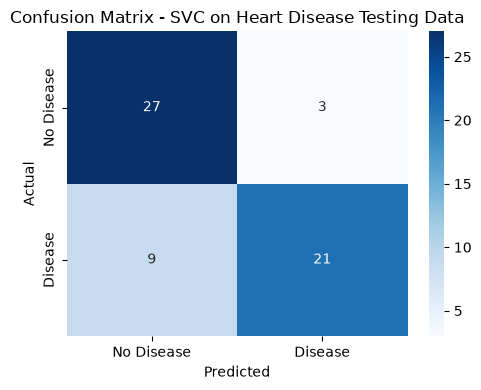

In [29]:
print(classification_report(
    testing_data["target"], testing_data["Predictions"],
    target_names=["No Disease (0)", "Disease (1)"]
))

conf_matrix = confusion_matrix(testing_data["target"], testing_data["Predictions"])
plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVC on Heart Disease Testing Data')
plt.tight_layout()
plt.show()

In [30]:
user_values = {}
for f in features:
    user_values[f] = [float(input(f"Please enter {f}: "))]

unseen_data_features = pd.DataFrame(user_values)
print(unseen_data_features)

Please enter thal:  7
Please enter ca:  2
Please enter oldpeak:  2.5
Please enter thalach:  120


   thal   ca  oldpeak  thalach
0   7.0  2.0      2.5    120.0


Not needed. The user input is already numeric.

In [31]:
model = pickle.load(open('svc_trained_model.pkl', 'rb'))
predicted = model.predict(unseen_data_features)

prediction = "HEART DISEASE" if predicted[0] == 1 else "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|         HEART DISEASE          |
+--------------------------------+


In [32]:
import sklearn
print(sklearn.__version__)

1.9.0
